# Sine waveform generation
_In the context of sound synthesis_

## Content
- sinewave in the continuous domain: 
- sinewave in the discrete domain: calculate the sine output for each sample
- issues when changing the frequency
- using phase instead of sample index
- pseudo code


___
## Continuous sine waveform 

### Simple sin function

In order to generate a sine wavevorm, we need to use the sin function. 

Let's first apply sin to x in the continuous domain as follows:  

`function(x) = sin(x)`

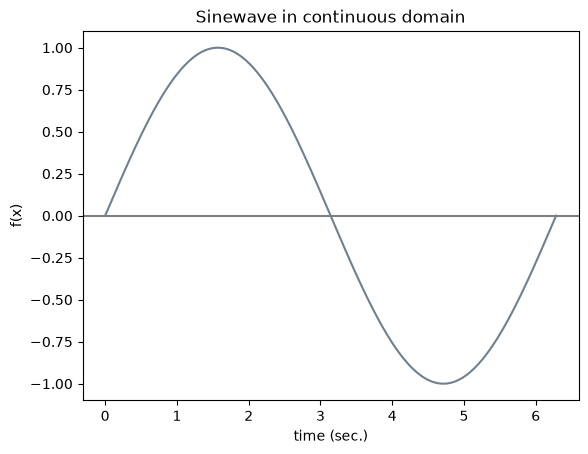

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

"""
numpy.linspace(start, stop, num=50)
    num: int, optional
    Number of samples to generate. Default is 50. Must be non-negative.
see https://numpy.org/doc/stable/reference/generated/numpy.linspace.html
"""

# Generate x values, evenly spaced numbers (number of represented by num) over given interval [0, 2pi] 
x = np.linspace(0, 2 * np.pi, 500)

# Generate plot for x representing [0, 2pi] and the sin function
plt.plot(x, np.sin(x))

plt.xlabel("time (sec.)")
plt.ylabel("f(x)")
plt.title("Sinewave in continuous domain")
# display x axis and show plot
plt.axhline(0, color = "gray")
plt.show()

### Function of time

Now, instead of using x in our function, let's implement our function as a function in time and use t. 
Additionally, map our sine wave to a period of 1 second. Herefore, we need to multiply t with 2pi.  

`function(t) = sin(2 * pi * t)`


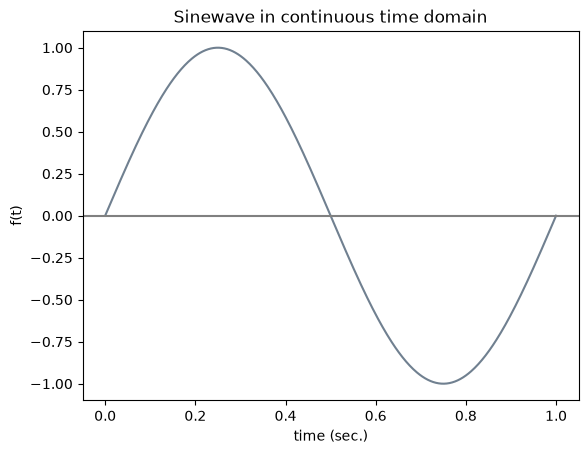

In [103]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

# Generate t values, evenly spaced numbers (number of represented by num) over given interval [0, 1] 
t = np.linspace(0, 1, 500)

# Create a plot of a sine wave with frequency 1 in the continuous domain expessed as t. 
# NOTE: we need to multiply t with 2pi to ensure one wave form is finished in 1 second
plt.plot(t, np.sin(2 * np.pi * t))


plt.xlabel("time (sec.)")
plt.ylabel("f(t)")
plt.title("Sinewave in continuous time domain")
plt.axhline(0, color = "gray")
plt.show()

### Frequency

Now, let us also consider the frequency. The previous function displayed a sinewave with a frequency of 1 Hz; one cycle in one second. 

`function(t) = sin(2 * pi * t)`

A waveform with a frequency of 2 Hz completes its cycle twice per second. In order to let the waveform progress twice as fast, we can simply add a multiplication with two:

`function(t) = sin(2 * 2 * pi * t)`

A waveform with a frequency of 0.5 Hz, only traverses a half cycle per second. For this frequency, we can multilpy with 0.5: 

`function(t) = sin(0.5 * 2 * pi * t)`

Concluding; we can extend our the function of a sine wave generation in continious time domain with the frequency by simply adding a multiplication with the frequency as follows: 

`function(t) = sin(freq * 2 * pi * t)`




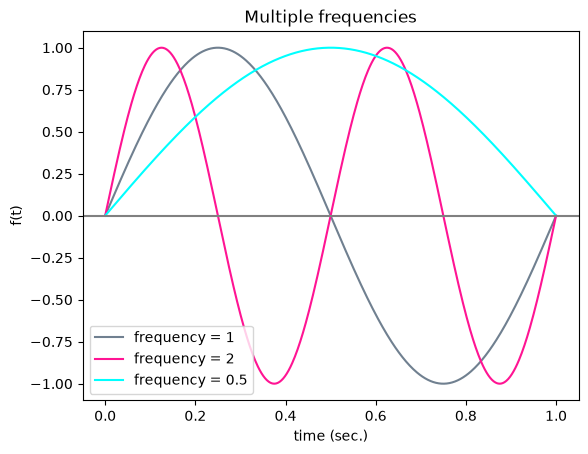

In [98]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

# Generate t values, evenly spaced numbers (number of represented by num) over given interval [0, 1] 
t = np.linspace(0, 1, 500)

# AGAIN - generate a plot of a sine in the continuous domain expessed as t
# but now two times, one wave with freq 1Hz and one with freq 3Hz
freq1 = 1
freq2 = 2
freq05 = 0.5
plt.plot(t, np.sin(freq1 * 2 * np.pi * t), label = "frequency = 1")
plt.plot(t, np.sin(freq2 * 2 * np.pi * t), label = "frequency = 2")
plt.plot(t, np.sin(freq05 * 2 * np.pi * t), label = "frequency = 0.5")

plt.xlabel("time (sec.)")
plt.ylabel("f(t)")
plt.legend()
plt.title("Multiple frequencies")
plt.axhline(0, color = "gray")
plt.show()

___
## Discrete domain

Generating a sine wave on a computer takes place in the discrete domain rather than in the continuous domain. Therefore, we transform our continuous function into a discrete function. 

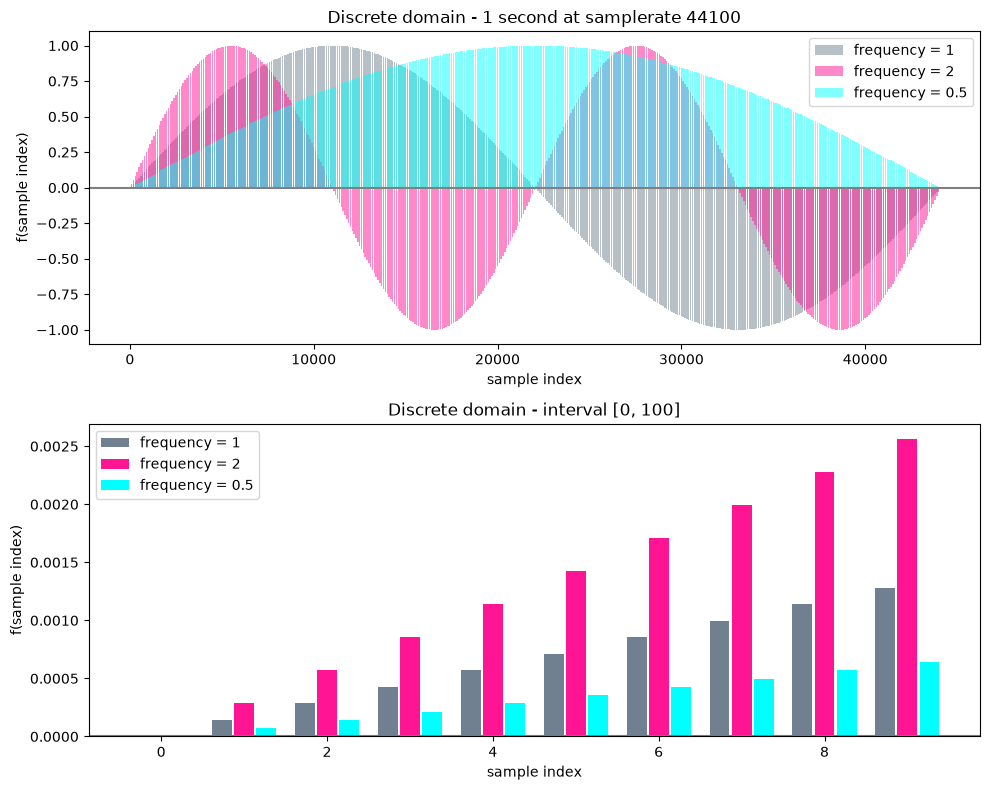

In [108]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

freq1 = 1
freq2 = 2
freq05 = 0.5

def get_sine_output(frequency, sample_index, samplerate):
    return np.sin(
        (frequency * 2 * np.pi * sample_index) / 
        samplerate
    )

# create two plots at once, one for 44100 samples and one zoomed in --> use subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.set_prop_cycle(color_cycle)
ax2.set_prop_cycle(color_cycle)

# ============ Discrete domain [0, 44100] sample indices =============

# Generate sample index values
samplerate = 44100
sample_indices = np.arange(0, samplerate, 100)

# outputs
y1 = get_sine_output(freq1, sample_indices, samplerate)
y2 = get_sine_output(freq2, sample_indices, samplerate)
y05 = get_sine_output(freq05, sample_indices, samplerate)

# gen bar plots
ax1.bar(sample_indices, y1, width = step_size * 0.8, alpha = 0.5, label = "frequency = 1")
ax1.bar(sample_indices, y2, width = step_size * 0.8, alpha = 0.5, label = "frequency = 2")
ax1.bar(sample_indices, y05, width = step_size * 0.8, alpha = 0.5, label = "frequency = 0.5")

# add line, title, lables and legend
ax1.axhline(0, color = "gray")
ax1.set_title("Discrete domain - 1 second at samplerate " + str(samplerate))
ax1.set_xlabel("sample index")
ax1.set_ylabel("f(sample index)")
ax1.legend()

# ============ Discrete domain [0, 100] sample indices =============

# Generate sample index values
min_sample_index = 0
max_sample_index = 10;
sample_indices = np.arange(min_sample_index, max_sample_index)

# outputs
y1 = get_sine_output(freq1, sample_indices, samplerate)
y2 = get_sine_output(freq2, sample_indices, samplerate)
y05 = get_sine_output(freq05, sample_indices, samplerate)

# gen bar plots
# plot bars next to eachother instead of on top of eachother
w =  0.8 / 3.0

ax2.bar(sample_indices - w, y1, width = w * 0.9, alpha = 1, label = "frequency = 1")
ax2.bar(sample_indices, y2, width = w * 0.9, alpha = 1, label = "frequency = 2")
ax2.bar(sample_indices + w, y05, width = w * 0.9, alpha = 1, label = "frequency = 0.5")
# uncomment below to display full y axis from -1 to 1
#plt.axis([min_sample_index, max_sample_index, -1, 1]) 

# add line, title, lables and legend
ax2.axhline(0, color = "gray")
ax2.set_title("Discrete domain - interval [0, 100]")
ax2.set_xlabel("sample index")
ax2.set_ylabel("f(sample index)")
ax2.legend()

# Adjust spacing so labels do not overlap
plt.tight_layout()
plt.show()

### Periodic waveforms and frequency changes

We can distinquish two issues regarding the latter approach, where we use a function to calculate the output per sample: 
- The sample index 'grows' extremely large, is this really necessary for a periodic function?
- What happens when we change the frequency?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

freq1 = 1
freq2 = 2
freq05 = 0.5

def get_sine_output(frequency, sample_index, samplerate):
    return np.sin(
        (frequency * 2 * np.pi * sample_index) / 
        samplerate
    )

# create two plots at once, one for 44100 samples and one zoomed in --> use subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.set_prop_cycle(color_cycle)
ax2.set_prop_cycle(color_cycle)

# ============ Discrete domain [0, 44100] sample indices =============

# Generate sample index values
samplerate = 44100
sample_indices = np.arange(0, samplerate, 100)

# outputs
y1 = get_sine_output(freq1, sample_indices, samplerate)
y2 = get_sine_output(freq2, sample_indices, samplerate)
y05 = get_sine_output(freq05, sample_indices, samplerate)

# gen bar plots
ax1.bar(sample_indices, y1, width = step_size * 0.8, alpha = 0.5, label = "frequency = 1")
ax1.bar(sample_indices, y2, width = step_size * 0.8, alpha = 0.5, label = "frequency = 2")
ax1.bar(sample_indices, y05, width = step_size * 0.8, alpha = 0.5, label = "frequency = 0.5")

# add line, title, lables and legend
ax1.axhline(0, color = "gray")
ax1.set_title("Discrete domain - 1 second at samplerate " + str(samplerate))
ax1.set_xlabel("sample index")
ax1.set_ylabel("f(sample index)")
ax1.legend()
